In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content/drive/MyDrive/ColabNotebooks/IS110_BPerformance_Hallador/IS110_repo_Hallador/ICT110_AppDev_Hallador/

/content/drive/MyDrive/ColabNotebooks/IS110_BPerformance_Hallador/IS110_repo_Hallador/ICT110_AppDev_Hallador


In [3]:
!pwd

/content/drive/MyDrive/ColabNotebooks/IS110_BPerformance_Hallador/IS110_repo_Hallador/ICT110_AppDev_Hallador


In [5]:
ls

'Copy of Copy of (IS110)Using_Git on Google Colab.ipynb'
 Datasets/
 Exercises_Hallador.ipynb
 ML_Workbook_Wisconsin_Diagnostic_Hallador.ipynb


<a id='lesson2'></a>

# 2. Saving and Loading of DataFrames to/from Files  

## Exercise 2.1

Load to a dataframe the file `GDP(PPP)_LifeExpectancy.xlsx` in the folder `Datasets`.
- Don't load the column Code which contains the full name of the country
- Use the following column names: 'Country', 'Life_Exp', 'GDP', 'Population', 'Inc_Class'
- Encode invalid values to `np.nan`

In [7]:
import pandas as pd, numpy as np

# Load data and filter invalid rows directly
raw = pd.read_excel('Datasets/GDP(PPP)_LifeExpectancy.xlsx', na_values=['..', '', 'N/A', 'NA']).dropna(subset=['Country Name', 'Series Name'])

# Pivot table and clean column index name
df_gdp = raw.pivot_table(index='Country Name', columns='Series Name', values='2023 [YR2023]', aggfunc='first').reset_index()
df_gdp.columns.name = None

# Dynamic column mapping
col_map = {'country': 'Country', 'life': 'Life_Exp', 'gdp': 'GDP', 'population': 'Population'}
df_gdp.rename(columns={col: next((v for k, v in col_map.items() if k in str(col).lower()), col) for col in df_gdp.columns}, inplace=True)

# Ensure required columns exist and order them
target_cols = ['Country', 'Life_Exp', 'GDP', 'Population', 'Inc_Class']
df_gdp = df_gdp.reindex(columns=target_cols)

df_gdp.head()

,Country,Life_Exp,GDP,Population,Inc_Class
0,Afghanistan,66.035,2201.722907,NaN,NaN
1,Albania,79.602,21259.797781,NaN,NaN
2,Algeria,76.261,16824.487903,NaN,NaN
3,American Samoa,72.852,NaN,NaN,NaN
4,Andorra,84.041,71730.668682,NaN,NaN


<a id='lesson3'></a>

# 3. Basic Plotting

## Exercise 3.1

<a id='lesson3'></a>

The BitCoin Year-on-Year price data in CSV format could be found in this link: https://api.blockchain.info/charts/market-price?format=csv.
1. Download a copy of the CSV file and observe its characteristics.
2. Load the file directly from the url/website and assign it to a DataFrame called `df_bitcoin`
3. Plot the data

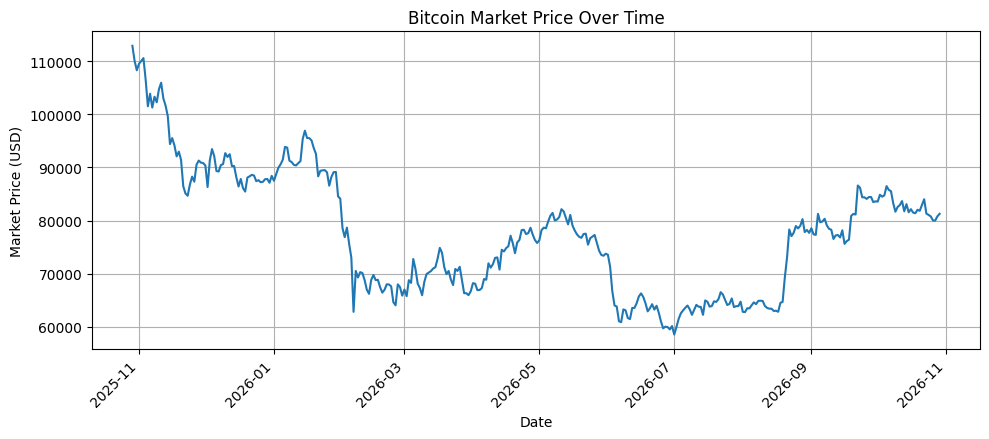

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Load and format Bitcoin price data
url = 'https://api.blockchain.info/charts/market-price?format=csv'
df_bitcoin = pd.read_csv(url, header=None, names=['Date', 'Price'], parse_dates=['Date'])

# Plot time series
plt.figure(figsize=(10, 4.5))
plt.plot(df_bitcoin['Date'], df_bitcoin['Price'])

# Styling
plt.title('Bitcoin Market Price Over Time')
plt.xlabel('Date')
plt.ylabel('Market Price (USD)')
plt.grid(True)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

<a id='lesson4'></a>

# 4. Viewing Data

## Exercise 4.1

Answer the following questions regarding the `df_gdp` you created in Exercise 2.1:
  1. What are the dimensions of the DataFrame?
  2. How many valid GDP values are there?
  3. What is the average life expectancy for all countries?
  4. Sort the dataframe by Country and assign it to a new DataFrame
  5. What are the top 5 countries with the highest GDP?          
  6. What are the top 5 countries with smallest population?

### 1. What are the dimensions of the DataFrame?

In [ ]:
print(df_gdp.shape)

(217, 5)


### 2. How many valid GDP values are there?

In [ ]:
print(df_gdp['GDP'].notna().sum())


197


### 3. What is the average life expectancy for all countries?

In [ ]:
print("Average life expectancy:", round(df_gdp['Life_Exp'].mean(), 2))

Average life expectancy: 73.8


### 4. Sort the dataframe by Country and assign it to a new DataFrame

In [ ]:
df_gdp_sorted = df_gdp.sort_values('Country').reset_index(drop=True)

print("DataFrame created.")

DataFrame created.


### 5. What are the top 5 countries with the highest GDP?

In [ ]:
df_gdp.nlargest(5, 'GDP')[['Country', 'GDP']]

,Country,GDP
171,Singapore,143786.136293
116,Luxembourg,142424.729887
159,Qatar,128918.549293
93,Ireland,124900.938635
117,"Macao SAR, China",116491.377162


### 6. What are the top 5 countries with smallest population?

In [9]:
import pandas as pd

# Load dataset
df = pd.read_csv('Datasets/WorldBank_WHO_Country_Dataset_2015.csv')

# Map country codes to full names
iso_map = {'NRU': 'Nauru', 'TUV': 'Tuvalu', 'PLW': 'Palau', 'SMR': 'San Marino', 'GIB': 'Gibraltar'}
df['Country'] = df['Country'].map(lambda x: iso_map.get(x, x))

# Get top 5 countries with smallest population
df[['Country', 'Population']].dropna().sort_values('Population').head(5)

,Country,Population
175,Nauru,10954
241,Tuvalu,10963
184,Palau,17770
208,San Marino,32897
84,Gibraltar,33193
